# 06 Folds and metrics

Defines the chronological folds and the tail metrics (D-003, D-004) used to compare every model, checks that both behave as intended, and scores the baselines on them. Development days only. Code lives in `notebooks/_eval.py`.

## Init

In [1]:
import sys
sys.path[:0] = ["notebooks", "."]  # _common imports from repo root or notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from _common import load, to_uk, dev_only
from _eval import make_folds, score

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 60)

plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 100})

T = pd.read_parquet("outputs/feature_table_dev.parquet")
days = pd.DatetimeIndex(sorted(T["day"].unique()))
print(T.shape, "|", len(days), "days", days.min().date(), "to", days.max().date())

(64702, 41) | 674 days 2024-10-01 to 2026-08-05


## 1. Fold design

- Validation blocks of 28 days, tiled backwards from the end of the development period, so the block nearest the hold-out is complete. 17 blocks.
- Training days end at least `gap` = 1 full day before the first validation day. In production the run for day D happens on the morning of D-1, when D-1 prices are not complete, so the latest usable training day is D-2. The model is then held fixed across the 28-day block, which is slightly staler than daily retraining (conservative).
- Two training windows: expanding (all earlier days) and sliding (last 180 days). Sliding tests whether old data hurts because of the level drift.

In [2]:
exp = make_folds(days, block=28, n_folds=17, gap=1)
sli = make_folds(days, block=28, n_folds=17, gap=1, train_window=180)

rows = []
for e, s in zip(exp, sli):
    rows.append({"fold": e["fold"], "val_start": e["val_days"][0].date(), "val_end": e["val_days"][-1].date(),
                 "train_end": e["train_days"][-1].date(), "n_train_expanding": len(e["train_days"]),
                 "n_train_sliding": len(s["train_days"])})
F = pd.DataFrame(rows)
print(F.to_string(index=False))

# structural checks
for f in exp + sli:
    assert f["train_days"].max() < f["val_days"].min() - pd.Timedelta(days=1)       # gap of at least one day
    assert len(set(f["train_days"]) & set(f["val_days"])) == 0
vals = np.concatenate([f["val_days"].values for f in exp])
assert len(vals) == len(set(vals))                                                    # validation blocks do not overlap
assert exp[-1]["val_days"][-1] == days.max()                                          # last block ends at the end of dev
print("\nfold checks passed;", len(vals), "validation days in total")

 fold  val_start    val_end  train_end  n_train_expanding  n_train_sliding
    0 2025-04-17 2025-05-14 2025-04-15                197              180
    1 2025-05-15 2025-06-11 2025-05-13                225              180
    2 2025-06-12 2025-07-09 2025-06-10                253              180
    3 2025-07-10 2025-08-06 2025-07-08                281              180
    4 2025-08-07 2025-09-03 2025-08-05                309              180
    5 2025-09-04 2025-10-01 2025-09-02                337              180
    6 2025-10-02 2025-10-29 2025-09-30                365              180
    7 2025-10-30 2025-11-26 2025-10-28                393              180
    8 2025-11-27 2025-12-24 2025-11-25                421              180
    9 2025-12-25 2026-01-21 2025-12-23                449              180
   10 2026-01-22 2026-02-18 2026-01-20                477              180
   11 2026-02-19 2026-03-18 2026-02-17                505              180
   12 2026-03-19 2026-04-

## 2. Metrics

For a frame with `day`, `price` and a prediction column:

- **MAE, RMSE, bias** (prediction minus actual).
- **Within-day top-8 / bottom-8 hit rate** (headline): for each day, the share of the 8 periods the forecast ranks highest (lowest) that are also among the actual 8 highest (lowest). Days where the forecast has fewer than 5 distinct values (a constant) are skipped. Random choice scores 8/48 = 0.167.
- **MAE on the actual top and bottom decile periods**, with the deciles taken from the scored sample. Read next to MAE.
- **Pinball loss at 10% and 90%** for quantile forecasts.

First check each metric on cases with known answers.

In [3]:
chk = T[T["cutoff_hour"] == 9].dropna(subset=["price"]).copy()
rng = np.random.default_rng(0)
chk["oracle"] = chk["price"]
chk["reversed"] = -chk["price"]
chk["const"] = chk["price"].median()
chk["noise"] = rng.normal(size=len(chk))
chk["oracle_q10"] = chk["price"] - 20
chk["oracle_q90"] = chk["price"] + 20
r = pd.DataFrame({k: score(chk, k) for k in ["oracle", "reversed", "const", "noise"]}).T
print(r.round(3).to_string())
assert r.loc["oracle", "MAE"] == 0 and r.loc["oracle", "hit_top8"] == 1 and r.loc["oracle", "hit_bot8"] == 1
assert r.loc["reversed", "hit_top8"] < 0.05 and r.loc["reversed", "hit_bot8"] < 0.05
assert 0.14 < r.loc["noise", "hit_top8"] < 0.20
assert np.isnan(r.loc["const", "hit_top8"])
s = score(chk, "oracle", q10="oracle_q10", q90="oracle_q90")
print("pinball with quantiles 20 below / above the truth:", round(s["pinball10"], 3), round(s["pinball90"], 3),
      "(expected 0.1*20=2.0 and 0.1*20=2.0)")
assert abs(s["pinball10"] - 2.0) < 1e-9 and abs(s["pinball90"] - 2.0) < 1e-9

                n      MAE     RMSE     bias  MAE_top10  MAE_bot10  hit_top8  hit_bot8  hit_days
oracle    32351.0    0.000    0.000    0.000      0.000      0.000     1.000     1.000     674.0
reversed  32351.0  176.180  216.867 -172.543    331.581     26.857     0.000     0.000     674.0
const     32351.0   34.000   65.725    2.178     77.340     93.198       NaN       NaN       0.0
noise     32351.0   88.094  108.436  -86.268    165.804     13.504     0.162     0.172     674.0
pinball with quantiles 20 below / above the truth: 2.0 2.0 (expected 0.1*20=2.0 and 0.1*20=2.0)


## 3. Quantile baseline

For pinball loss, the baseline quantiles are the empirical 10% and 90% of the same clock time over D-29..D-2 (same look-back as the 28-day median, so they use only prices known at both cutoffs).

In [4]:
price = dev_only(load("imbalance_price")).set_index("period_start")["price_gbp_per_mwh"]
loc = to_uk(price.index.to_series())
dfp = pd.DataFrame({"price": price, "day": loc.dt.tz_localize(None).dt.normalize(), "hhmm": loc.dt.strftime("%H:%M")})
dfp["occ"] = dfp.groupby(["day", "hhmm"]).cumcount()
wide = dfp.pivot(index="day", columns=["hhmm", "occ"], values="price")
wide = wide.reindex(pd.date_range(wide.index.min(), wide.index.max(), freq="D"))
known = wide.shift(2)

def to_long(Fm):
    ri = Fm.index.get_indexer(dfp["day"])
    ci = Fm.columns.get_indexer(pd.MultiIndex.from_arrays([dfp["hhmm"], np.zeros(len(dfp), dtype=int)]))  # by clock time: the repeated autumn hour reads the history of the first
    out = np.full(len(dfp), np.nan)
    ok = (ri >= 0) & (ci >= 0)
    out[ok] = Fm.to_numpy()[ri[ok], ci[ok]]
    return pd.Series(out, index=dfp.index)

Q = pd.DataFrame({"q10_28": to_long(known.rolling(28, min_periods=14).quantile(0.1)),
                  "q90_28": to_long(known.rolling(28, min_periods=14).quantile(0.9))})
T = T.merge(Q, left_on="period_start", right_index=True, how="left")
print(T[["q10_28", "q90_28"]].notna().mean().round(3).to_string())
cov = T.dropna(subset=["q10_28", "price"])
print("share of actual prices below q10 / above q90 (nominal 10% each):",
      round((cov["price"] < cov["q10_28"]).mean(), 3), round((cov["price"] > cov["q90_28"]).mean(), 3))

q10_28    0.978
q90_28    0.978
share of actual prices below q10 / above q90 (nominal 10% each): 0.131 0.138


## 4. Baselines on the folds

Baselines are not fitted, so training windows do not matter here; this scores them on the 17 validation blocks (476 days, from the first block onward) so that later models are compared on exactly the same rows. Pooled over all validation rows at the 09:00 cutoff, then by fold.

In [5]:
val_days_all = pd.DatetimeIndex(np.concatenate([f["val_days"].values for f in exp]))
V = T[T["day"].isin(val_days_all)]
V9 = V[V["cutoff_hour"] == 9]

base = {"med28_same": dict(q10="q10_28", q90="q90_28"), "med7_same": {}, "d2_same": {}, "level24h": {}, "level28": {}}
pooled = pd.DataFrame({k: score(V9, k, **kw) for k, kw in base.items()}).T
print("pooled, 09:00 cutoff,", len(V9), "rows")
print(pooled.round(3).to_string())

pooled, 09:00 cutoff, 22847 rows
                  n     MAE    RMSE   bias  MAE_top10  MAE_bot10  hit_top8  hit_bot8  hit_days  pinball10  pinball90
med28_same  22847.0  30.202  42.232  1.895     49.103     82.273     0.462     0.322     476.0      8.156      6.285
med7_same   22847.0  32.147  44.807  1.914     46.734     79.343     0.410     0.272     476.0        NaN        NaN
d2_same     22844.0  39.749  55.937 -0.096     52.301     76.424     0.340     0.247     476.0        NaN        NaN
level24h    22847.0  34.965  48.540 -0.140     57.059     82.243       NaN       NaN       0.0        NaN        NaN
level28     22847.0  32.131  44.427 -0.600     61.956     87.830       NaN       NaN       0.0        NaN        NaN


In [6]:
perf = []
for f in exp:
    d = V9[V9["day"].isin(f["val_days"])]
    s = score(d, "med28_same", q10="q10_28", q90="q90_28")
    s["fold"] = f["fold"]; s["val_start"] = f["val_days"][0].date()
    s["price_median"] = d["price"].median()
    perf.append(s)
PF = pd.DataFrame(perf).set_index("fold")
print(PF[["val_start", "n", "price_median", "MAE", "RMSE", "bias", "MAE_top10", "MAE_bot10", "hit_top8", "hit_bot8", "pinball10", "pinball90"]].round(2).to_string())
print()
print("across folds: mean / std")
print(pd.DataFrame({"mean": PF[["MAE", "RMSE", "hit_top8", "hit_bot8", "pinball10", "pinball90"]].mean(),
                    "std": PF[["MAE", "RMSE", "hit_top8", "hit_bot8", "pinball10", "pinball90"]].std()}).round(3).to_string())

       val_start     n  price_median    MAE   RMSE   bias  MAE_top10  MAE_bot10  hit_top8  hit_bot8  pinball10  pinball90
fold                                                                                                                     
0     2025-04-17  1344         79.40  24.87  32.82  -1.01      39.27      58.99      0.48      0.33       6.79       4.88
1     2025-05-15  1344         64.68  36.38  45.11  11.95      35.03      83.90      0.42      0.37       9.06       6.01
2     2025-06-12  1344         83.48  39.99  52.40   2.38      53.97      92.97      0.44      0.38       9.11       7.39
3     2025-07-10  1344         70.00  25.82  33.91   2.49      31.74      67.45      0.33      0.26       8.84       4.45
4     2025-08-07  1344         72.85  27.16  35.98  -2.28      47.37      74.20      0.39      0.24       7.40       5.20
5     2025-09-04  1344         66.25  35.03  45.34   7.79      36.08      90.14      0.54      0.26      11.40       6.00
6     2025-10-02  1346  

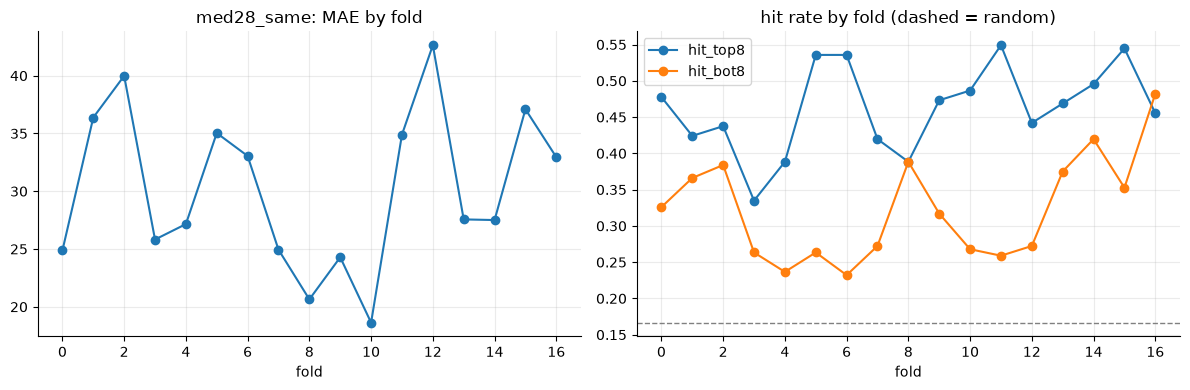

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
PF["MAE"].plot(ax=axes[0], marker="o"); axes[0].set_title("med28_same: MAE by fold"); axes[0].set_xlabel("fold")
PF[["hit_top8", "hit_bot8"]].plot(ax=axes[1], marker="o"); axes[1].axhline(8 / 48, color="grey", ls="--", lw=1)
axes[1].set_title("hit rate by fold (dashed = random)"); axes[1].set_xlabel("fold")
plt.tight_layout(); plt.show()

## 5. 07:00 against 09:00 for the price baselines

The price baselines differ across cutoffs only through `level24h`, so this mostly shows that the metrics are not sensitive to the cutoff for these baselines.

In [8]:
out = {}
for h in (7, 9):
    d = V[V["cutoff_hour"] == h]
    out[f"{h:02d}:00 med28_same"] = score(d, "med28_same", q10="q10_28", q90="q90_28")
    out[f"{h:02d}:00 level24h"] = score(d, "level24h")
print(pd.DataFrame(out).T.round(3).to_string())

                        n     MAE    RMSE   bias  MAE_top10  MAE_bot10  hit_top8  hit_bot8  hit_days  pinball10  pinball90
07:00 med28_same  22847.0  30.202  42.232  1.895     49.103     82.273     0.462     0.322     476.0      8.156      6.285
07:00 level24h    22847.0  35.182  48.846 -0.496     57.786     82.093       NaN       NaN       0.0        NaN        NaN
09:00 med28_same  22847.0  30.202  42.232  1.895     49.103     82.273     0.462     0.322     476.0      8.156      6.285
09:00 level24h    22847.0  34.965  48.540 -0.140     57.059     82.243       NaN       NaN       0.0        NaN        NaN


## Findings

- **Folds.** 17 validation blocks of 28 days tiled back from the end of the development period (2025-04-17 to 2026-08-05, 476 days). Training ends 1 full day before each block (D-2 for the first validation day, as in production). Expanding windows run from 197 to 645 days; sliding windows are 180 days. Structural checks pass (no overlap, gap respected, last block ends at the end of dev).
- **Metrics behave correctly** on cases with known answers: an oracle gets MAE 0 and hit rate 1; a reversed forecast gets hit rate 0; random noise gets about 0.17 (random level 8/48); a constant forecast is skipped for hit rates; the pinball formula returns the exact expected value.
- **Reference scores (09:00 cutoff, pooled over the 476 validation days, 22,847 rows).** 28-day same-period median: MAE 30.2, RMSE 42.2, bias +1.9, hit rate 0.462 top-8 / 0.322 bottom-8, pinball 8.16 (10%) / 6.29 (90%). 7-day median: MAE 32.1, hit 0.41 / 0.27. D-2 same period: MAE 39.8, hit 0.34 / 0.25. 24 h level: MAE 35.0. 28-day level: MAE 32.1.
- **These numbers are not comparable with notebook 04.** RMSE here is 42 against 63.5 there because the validation days start in April 2025 and so exclude the early-2025 spike period (including the 2,900 price). Compare models only with each other on these folds.
- **Fold-to-fold spread is large.** For the 28-day median, MAE ranges from 18.6 to 42.6 across folds (std 6.9 on a mean of 30.2) and the top-8 hit rate from 0.33 to 0.55 (std 0.06). A model has to be compared with the baseline fold by fold (paired); a difference of a pound or two in pooled MAE is well inside this spread unless it is consistent across folds.
- **The decile MAE can reward the wrong thing.** The 7-day median has a better top-decile MAE (46.7) than the 28-day median (49.1) but worse overall MAE and hit rate. That is why it is only read next to MAE.
- **The baseline quantiles are too narrow.** Actual prices fall below the 28-day 10% quantile 13.1% of the time and above the 90% quantile 13.8%, instead of 10% each, because history underestimates the tails when the level moves. A quantile model should beat this on coverage as well as pinball loss.
- **Cutoff.** The price baselines give identical scores at 07:00 and 09:00 apart from `level24h` (MAE 35.2 vs 35.0), as expected; differences between cutoffs will have to come from the demand forecast.
- **Fold 16 (2026-07-09 to 2026-08-05) has a median price of £118,** closest to the hold-out period's level, so its results deserve particular attention.
